# Validation of temperatures agains Zhou et al (2025) and Schmidtko et al (2014)

In [1]:
import intake
import re
import glob
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import netCDF4 as nc
import cartopy.crs as ccrs
import xarray as xr
import cmocean as cm
import glob
import matplotlib.colors as col
import cf_xarray as cf
# need to install opencv-python for this:
import cv2
import warnings
import logging
from scipy.ndimage import distance_transform_edt
import scipy.ndimage as nd
from scipy.interpolate import griddata
from matplotlib.animation import FuncAnimation
import imageio.v3 as iio
import glob
import imageio.v3 as iio
import cmocean.cm as cm
import pandas as pd

logging.captureWarnings(True)
logging.getLogger('py.warnings').setLevel(logging.ERROR)

from dask.distributed import Client

In [2]:
client = Client(threads_per_worker = 1)

In [3]:
catalog = intake.cat.access_nri

def importer(experiment,catalog,variable, frequency = 'fx',start_time=0,end_time=0,chunks=''):
    xarray_open_kwargs = {"chunks": chunks,'decode_timedelta':True}
    var = catalog[experiment].search(variable=variable, frequency = frequency).to_dask(xarray_open_kwargs=xarray_open_kwargs)
    if start_time!=0:
        time_slice='slice(start_time,end_time)'
        return eval("var." + variable + ".sel(time=" + time_slice + ")")
    elif start_time ==0:
        return eval("var." + variable)

In [4]:
time_slice = slice('2007-01','2025-12')
lat_slice = slice(-90,-50)

In [5]:
# Importing monthly IAF Conservative temperatures and dzt
T_iaf = (importer('01deg_jra55v140_iaf_cycle3',catalog,variable='temp', frequency = '1mon',chunks='auto').sel(time=time_slice,yt_ocean=lat_slice).mean('time') -273.15).compute() #oC

In [6]:
#other variables
dzt = (importer('01deg_jra55v140_iaf_cycle3',catalog,variable='temp', frequency = '1mon',chunks='auto').sel(time=slice('2005-01','2005-12'),yt_ocean=lat_slice).mean('time')).mean(('xt_ocean','yt_ocean')).compute() #m
Zhou_2026 = xr.open_dataset('/g/data/x77/cy8964/ocean-ice-obs/OI_Climatology.nc')
Pauthenet = xr.open_mfdataset('/g/data/ik11/observations/Southern_Ocean_Climatology_PauthenetETAL2021/TS_Climato_Antarctic60S.nc').sel(lat=lat_slice)
WOA = xr.open_mfdataset('/g/data/ik11/observations/woa13/01/*.nc').sel(GRID_Y_T=lat_slice).mean('time')
Schmidtko = xr.open_mfdataset('/g/data/v45/rm2389/Schmidtko_Observations/AASW_Temp_Salt.nc').sel(lat=lat_slice)

In [7]:
#Reorganizing dimensions of the temperature
Zhou_CT = Zhou_2026.ct
lon_inaccess= Zhou_2026.longitude.isel(SCALAR=0).values
lon_inaccess[-1] = 179.9
lon_inaccess[lon_inaccess>80]= lon_inaccess[lon_inaccess>80]-360 #converting longitude to access style [-280, 80]
Zhou_CT['nx'] = lon_inaccess
Zhou_CT['ny'] = Zhou_2026.latitude.isel(SCALAR=0).values
Zhou_CT['nz'] = Zhou_2026.pressure.isel(SCALAR=0).values
Zhou_CT = Zhou_CT.sortby('nx')

In [8]:
#standard error for Zhou
Zhou_CT_error = Zhou_CT.copy()
Zhou_CT_error.values = Zhou_2026.ct_mse

In [9]:
#converting from pressure to depth
from gsw import z_from_p
Zhou_lat = ((Zhou_CT*0)+1) * Zhou_CT['ny']
Zhou_z = -z_from_p(Zhou_CT['nz'],Zhou_lat)
Zhou_CT['nz'] = Zhou_z.mean(('nx','ny')).values

In [10]:
# interpolating Zhou into access-OM2-01 grid
Zhou_CT_inaccess = Zhou_CT.interp(nx = T_iaf.xt_ocean, ny = T_iaf.yt_ocean, nz = T_iaf.st_ocean)#

In [11]:
#Interpoalting WOA
T_WOA = WOA.temp.interp(GRID_X_T = T_iaf.xt_ocean,GRID_Y_T = T_iaf.yt_ocean,ZT = T_iaf.st_ocean).compute()


In [12]:
#fixing Schmidtko coord 
Schmidtko_lon =Schmidtko.lon
Schmidtko_lon80 = Schmidtko_lon.where(Schmidtko_lon<=80).fillna(0)
Schmidtko_lon280 = (Schmidtko_lon.where(Schmidtko_lon>80) - 360).fillna(0)
Schmidtko_lon = Schmidtko_lon80 + Schmidtko_lon280
Schmidtko['lon'] = Schmidtko_lon 

#Tob schmidtkp
Tob_Schmidtko = Schmidtko.CT.interp(lon = T_iaf.xt_ocean,lat = T_iaf.yt_ocean).compute()

In [13]:
def top2_along_z(a):
    # sort along last axis, take largest 2, reverse so max is first
    return np.flip(np.sort(a, axis=-1)[..., -2:], axis=-1)

In [14]:
#creating land mask
ht = xr.open_dataset('/g/data/ik11/outputs/access-om2-01/01deg_jra55v13_ryf9091/output076/ocean/ocean_grid.nc').ht.sel(yt_ocean=lat_slice).compute()
land_mask = (ht*0).fillna(1)

For the temperature at the bottom, zhou dataset doesnt have the same bottom as OM2, so I will average the bottom 2 cells of zhou and use the same for access

In [15]:
# # Getting temeprature at the bottom in Zhou results
BT_Zhou_zind = (((Zhou_CT_inaccess*0)+1) * Zhou_CT_inaccess.st_ocean).fillna(0).argmax('st_ocean',skipna=True)
second_max = (BT_Zhou_zind-1); second_max=second_max.where(second_max>=0).fillna(0)
BT_Zhou_zind = xr.concat([BT_Zhou_zind, second_max], dim="st_ocean_ind").astype('int')
BT_Zhou = Zhou_CT_inaccess.isel(st_ocean = BT_Zhou_zind).mean('st_ocean_ind')
del second_max
# BT_Zhou = Zhou_CT_inaccess.where(Zhou_CT_inaccess.st_ocean>=BT_Zhou_z).mean('st_ocean')

# # # # Getting temeprature at the bottom in IAF
# # BT_iaf_z = (((T_iaf*0)+1) * T_iaf.st_ocean).max('st_ocean')
# #BT_iaf = T_iaf.sel(st_ocean=BT_Zhou_z.fillna(0),method='nearest')
# BT_iaf = T_iaf.where(Zhou_CT_inaccess.st_ocean>=BT_Zhou_z).mean('st_ocean')
BT_iaf_zind = (((T_iaf*0)+1) * T_iaf.st_ocean).fillna(0).argmax('st_ocean',skipna=True)
second_max = (BT_iaf_zind-1); second_max=second_max.where(second_max>=0).fillna(0)
BT_iaf_zind = xr.concat([BT_iaf_zind, second_max], dim="st_ocean_ind").astype('int')

BT_iaf = T_iaf.isel(st_ocean = BT_iaf_zind).mean('st_ocean_ind') 

In [16]:
#getting the mean temperature in the top 10 m of the model
Zhou_CT_10m = Zhou_CT_inaccess.sel(st_ocean=slice(0,10)).weighted(dzt).mean('st_ocean')
T_iaf_10m = T_iaf.sel(st_ocean=slice(0,10)).weighted(dzt).mean('st_ocean')

Setting up the plot

In [17]:
#setting up the plot configs, to make the plotting lines a bit easier and more standardized
from cmcrameri import cm as cmc
from matplotlib.path import Path
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

def ANOplot(da,
            ax=None,
           vmin=0,
           vmax=0.15,
           cmap='seismic',
           add_colorbar=True,
           linestyle='-',
           title='',
           fonttitle=12,
           titlepad=16,
           latlim=-55,
           cbartitle=''):

    if 'time' in da.dims:
        raise ValueError("Please select a single time slice before calling SIplot().")

    if ax is None:
        fig = plt.figure(figsize=(8,8))
        ax = plt.axes(projection=ccrs.SouthPolarStereo())
    else:
        fig = ax.figure

    ax.set_extent([-180, 180, -90, latlim], crs=ccrs.PlateCarree())

    # circular boundary
    theta = np.linspace(0, 2*np.pi, 200)
    center, radius = [0.5, 0.5], 0.5
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = Path(verts * radius + center)
    ax.set_boundary(circle, transform=ax.transAxes)

    pcm = ax.pcolormesh(
        da['xt_ocean'],
        da['yt_ocean'],
        da,
        transform=ccrs.PlateCarree(),
        shading='auto',
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        zorder=-1
    )

    #ax.plot(np.linspace(-280,80,160),(np.linspace(-280,80,160)*0)-64,color='k',linewidth=1,linestyle='--',zorder=300,transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='0.5')
    ax.coastlines(linewidth=0.8)

    gl = ax.gridlines(draw_labels=False,
                      linewidth=0.8,
                      linestyle='--',
                      color='0.35',   # darker gray
                      alpha=0.9,
                      x_inline=False,
                      y_inline=False)

    gl.top_labels = False
    gl.right_labels = False

    gl.xlocator = plt.FixedLocator([-140,-65,30,70,160])
    gl.ylocator = plt.FixedLocator([-64])

    gl.xformatter = LongitudeFormatter()
    gl.yformatter = LatitudeFormatter()

    ax.set_title(title, fontsize=fonttitle, pad=titlepad)

    if add_colorbar:
        cb = fig.colorbar(pcm, ax=ax, shrink=0.3, pad=0.1)
        cb.set_label(cbartitle)

    return pcm, ax

In [18]:
def shelf_mask_isobath(var):
    '''
    Masks ACCESS-OM2-01 variables by the region polewards of the 1000m isobath as computed using 
    a script contributed by Adele Morrison.
    Only to be used with ACCESS-OM2-0.1 output!
    '''
    contour_file = np.load('/g/data/ik11/grids/Antarctic_slope_contour_1000m.npz')
    
    shelf_mask = contour_file['contour_masked_above']
    yt_ocean = contour_file['yt_ocean']
    xt_ocean = contour_file['xt_ocean']
    
    # in this file the points along the isobath are given a positive value, the points outside (northwards) 
    # of the isobath are given a value of -100 and all the points on the continental shelf have a value of 0 
    # so we mask for the 0 values 
    shelf_mask[np.where(shelf_mask!=0)] = np.nan
    shelf_mask = shelf_mask+1
    shelf_map  = np.nan_to_num(shelf_mask)
    shelf_mask = xr.DataArray(shelf_mask, coords = [('yt_ocean', yt_ocean), ('xt_ocean', xt_ocean)])
    shelf_map  = xr.DataArray(shelf_map,  coords = [('yt_ocean', yt_ocean), ('xt_ocean', xt_ocean)])
    
    # then we want to multiply the variable with the mask so we need to account for the shape of the mask. 
    # The mask uses a northern cutoff of 59S.
    masked_var = var.sel(yt_ocean = slice(-90, -59.03)) * shelf_mask

    return masked_var, shelf_map

In [19]:
#getting the shelf values
Zhou_CT_10m_shelf, shelf_mask = shelf_mask_isobath(Zhou_CT_10m)
T_iaf_10m_shelf, shelf_mask = shelf_mask_isobath(T_iaf_10m)
BT_Zhou_shelf, shelf_mask = shelf_mask_isobath(BT_Zhou)
BT_iaf_shelf, shelf_mask = shelf_mask_isobath(BT_iaf)

In [20]:
def stereoplot(SST_WOA_shelf,n, title,cmap,norms,varname):
    
    proj = ccrs.PlateCarree()
    ax325 = plt.subplot(2,3,n, projection=ccrs.SouthPolarStereo())
    ax325.set_extent([-180, 180, -90, -60], proj)
    ax325.set_boundary(circle, transform=ax325.transAxes)
    latlag = 0
    gl = ax325.gridlines(draw_labels=False, color='darkgray')
    gl.xlocator = mticker.FixedLocator(np.arange(-180, 180, 30))
    label_lon = ['0°', '180°', '60°E', '120°W', '120°E', '60°W',
                 '90°E', '90°W', '30°E', '150°W', '150°E', '30°W']
    rot_lon = [0, 0, -60, -60, 60, 60, -90, 90, -30, -30, 30, 30]
    lat_lon_label = [-59.5+latlag, -58.7+latlag, -59.5+latlag, -58.5+latlag, -58.5+latlag, -59.2+latlag, -59.5+latlag, -59.2+latlag,
                     -59.5+latlag, -58.7+latlag, -58.7+latlag, -59.5+latlag] 
    for i, position in enumerate([0, 180, 60, -120, 120, -60, 90, -90,
                                  30, -150, 150, -30]):
        ax325.text(position, lat_lon_label[i], label_lon[i], rotation=rot_lon[i],
                horizontalalignment='center', verticalalignment='center',
                color='gray', fontsize=10, transform=proj)
    for j in range(70, 90, 10):
        label = str(j) + '°S'
        ax325.text(-135, -j+1.3, label, rotation=-48, horizontalalignment='center',
                verticalalignment='center', color='gray', fontsize=10,
                transform=proj)
    
    
    ax325.contourf(land_mask.xt_ocean.values,
                np.concatenate(([-90], land_mask.yt_ocean[1:].values)),
                land_mask, colors='dimgray', levels=[0.5, 2],
                transform=proj, rasterized=True, zorder=6)
    
    
    
    plt.contour(shelf_mask.xt_ocean, shelf_mask.yt_ocean-0.01, shelf_mask.fillna(0).values,
                levels=[0, 1], colors = 'lightgray', linewidth=.7,
                transform=proj,)
    
    #SST_WOA_shelf * mask
    p325 = ax325.pcolormesh(SST_WOA_shelf.xt_ocean, SST_WOA_shelf.yt_ocean,
                       SST_WOA_shelf,\
                       cmap=cmap, vmin=norms[0],vmax=norms[1],transform=proj,
                        zorder=0)
    
    
    
    
    
    
    pos = ax325.get_position()
    cax = plt.axes([pos.xmin+0.03, pos.ymin-0.04,
                    .6*(pos.xmax-pos.xmin), 0.02])
    
    title_indexes = ['a','b','c','d','e','f','g','h','i','j']
    cb325 = plt.colorbar(p325, orientation='horizontal', cax=cax, extend='max')
    cb325.ax.tick_params(labelsize=12)
    cb325.ax.set_xlabel(varname,fontsize=13)
    if n<=3:
        ax325.set_title(title,fontsize = 16)

import cartopy.crs as ccrs
import matplotlib.ticker as mticker
import matplotlib.path as mpath
# Compute a circle in axes coordinates, which we can use as a boundary
# for the map. We can pan/zoom as much as we like - the boundary will be
# permanently circular.
theta = np.linspace(0, 2*np.pi, 100)
center, radius = [0.5, 0.5], 0.5
verts = np.vstack([np.sin(theta), np.cos(theta)]).T
circle = mpath.Path(verts * radius + center)

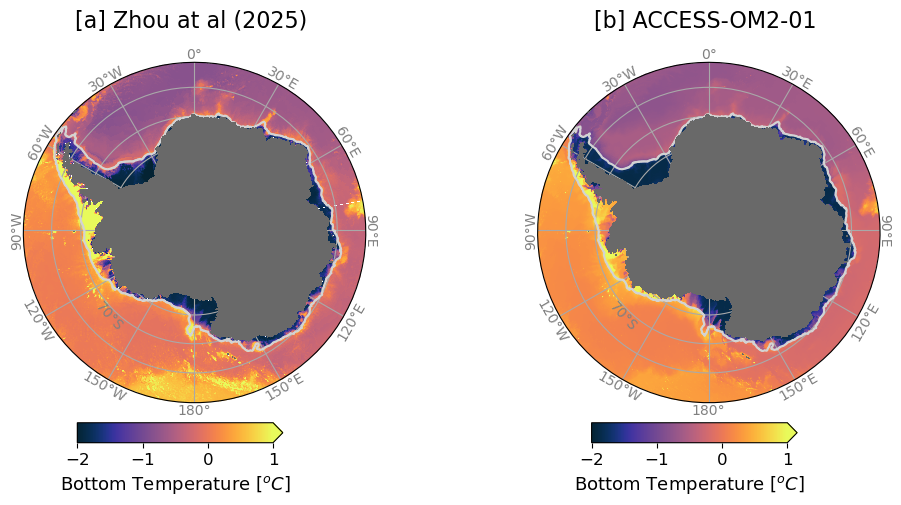

In [21]:
figure = plt.figure(num = 1, figsize = (18, 10))
plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.25,
                    hspace=0.35)

stereoplot(BT_Zhou.T,1,'[a] Zhou at al (2025) \n',cm.thermal,[-2,1],r'Bottom Temperature [$^oC$]')
stereoplot(BT_iaf,2,'[b] ACCESS-OM2-01 \n',cm.thermal,[-2,1],r'Bottom Temperature [$^oC$]')
plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/TOB_full.png',dpi=300,bbox_inches='tight')

Now more focused on the continental shelf and including schmidtko

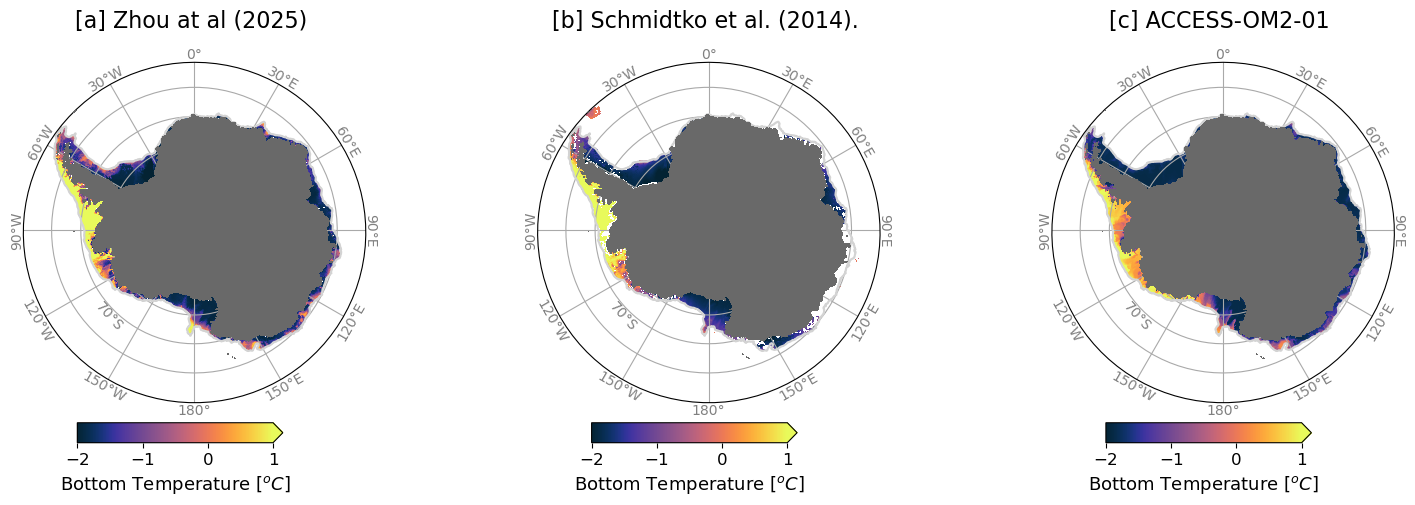

In [22]:
figure = plt.figure(num = 1, figsize = (18, 10))
plt.subplots_adjust(left=0.1,
                    bottom=0.1,
                    right=0.9,
                    top=0.9,
                    wspace=0.25,
                    hspace=0.35)

stereoplot(BT_Zhou_shelf.T,1,'[a] Zhou at al (2025) \n',cm.thermal,[-2,1],r'Bottom Temperature [$^oC$]')
stereoplot(Tob_Schmidtko,2,'[b] Schmidtko et al. (2014). \n',cm.thermal,[-2,1],r'Bottom Temperature [$^oC$]')
stereoplot(BT_iaf_shelf,3,'[c] ACCESS-OM2-01 \n',cm.thermal,[-2,1],r'Bottom Temperature [$^oC$]')
plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/TOB_shelf.png',dpi=300,bbox_inches='tight')

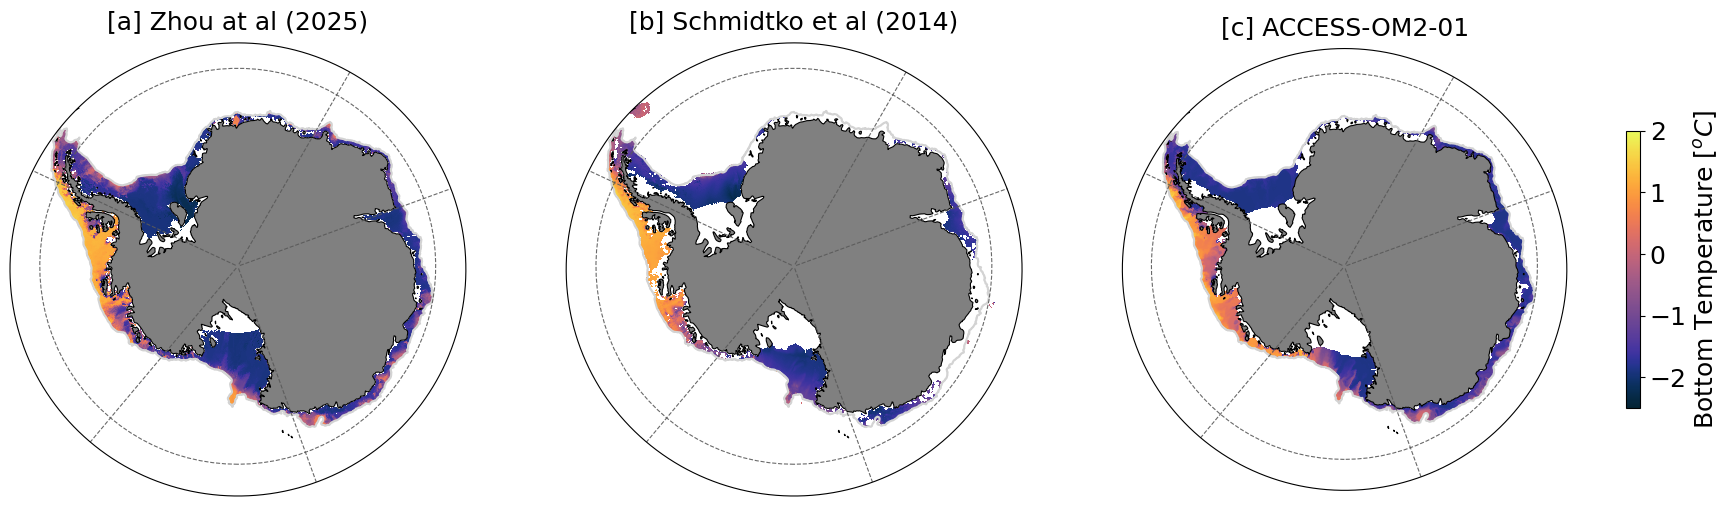

In [23]:
plt.rcParams.update({"font.size": 18})


fig = plt.figure(figsize=(22, 12))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1,1,1.3],
    hspace=0.1,)


#temperature limits
BTmin = -2.5
BTmax = 2


ax00 = fig.add_subplot(gs[0, 0],projection=ccrs.SouthPolarStereo())
ax01 = fig.add_subplot(gs[0, 1],projection=ccrs.SouthPolarStereo())
ax02 = fig.add_subplot(gs[0, 2],projection=ccrs.SouthPolarStereo())

# Zhou bottom temperature
shelf_mask.plot.contour(levels=[0.5,],colors='lightgray',ax=ax00,transform=ccrs.PlateCarree(),linzorder=0)
zhou_ASO_BT, _ = ANOplot(BT_Zhou_shelf.T,
                   ax=ax00,vmin=BTmin,vmax=BTmax,add_colorbar=False,cmap=cm.thermal,\
                   title=r'[a] Zhou at al (2025)',fonttitle=18,titlepad=10,latlim=-60)

# ACCESS
shelf_mask.plot.contour(levels=[0.5,],colors='lightgray',ax=ax01,transform=ccrs.PlateCarree(),linzorder=0)
SCHMITKO_ASO_BT, _ = ANOplot(Tob_Schmidtko,
                   ax=ax01,vmin=BTmin,vmax=BTmax,add_colorbar=False,cmap=cm.thermal,\
                   title=r'[b] Schmidtko et al (2014)',fonttitle=18,titlepad=10,latlim=-60)

# ACCESS
shelf_mask.plot.contour(levels=[0.5,],colors='lightgray',ax=ax02,transform=ccrs.PlateCarree(),linzorder=0)
OM2_ASO_BT, _ = ANOplot(BT_iaf_shelf,
                   ax=ax02,vmin=BTmin,vmax=BTmax,add_colorbar=False,cmap=cm.thermal,\
                   title=r'[c] ACCESS-OM2-01',fonttitle=18,titlepad=10,latlim=-60)


cb = fig.colorbar(zhou_ASO_BT, ax=ax02, shrink=0.3, pad=0.1) #creating colorbar 0
cb.set_label(r'Bottom Temperature [$^oC$]',fontsize=18) #labelling colorbar 0

plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/TOB_shelf2.png',dpi=300,bbox_inches='tight')

## Transects

Showing bottom properties might not be enough for the validation, we might need to look at some transects in key regions too.

In [24]:
vol_bins = xr.open_mfdataset('/g/data/x77/wf4500/ASC_project/volume_daily_10deg/OM2_01_iaf_cycle3/*.nc').isel(time=0)

In [25]:
longitude_inds = np.array([5,36-15, 14, 3,10,17,36-12,36-10, 36-1,1])
regions_abridged = ['Mertz','WAP', 'Getz', 'Totten',\
           'Glomar', 'Amundsen', 'Filchner', \
           'Riiser-Larsen', 'Amery', 'Denman']

In [26]:
print('Centre longitude of Amundsen is: ' + str(np.round(vol_bins.lon_bins[longitude_inds[5]].values,1)))

Centre longitude of Amundsen is: -103.5


In [27]:
print('Centre longitude of Totten is: ' + str(np.round(vol_bins.lon_bins[longitude_inds[3]].values,1)))

Centre longitude of Totten is: -243.5


In [28]:
print('Centre longitude of the 110E bin is is: ' + str(np.round(vol_bins.lon_bins[2].values,1)))

Centre longitude of the 110E bin is is: -253.5


### Amundsen Transect

In [29]:
Amundsen_lon_slice = slice(-103.5-5,-103.5+5)
Amundsen_lat_slice = slice(-78,-70)

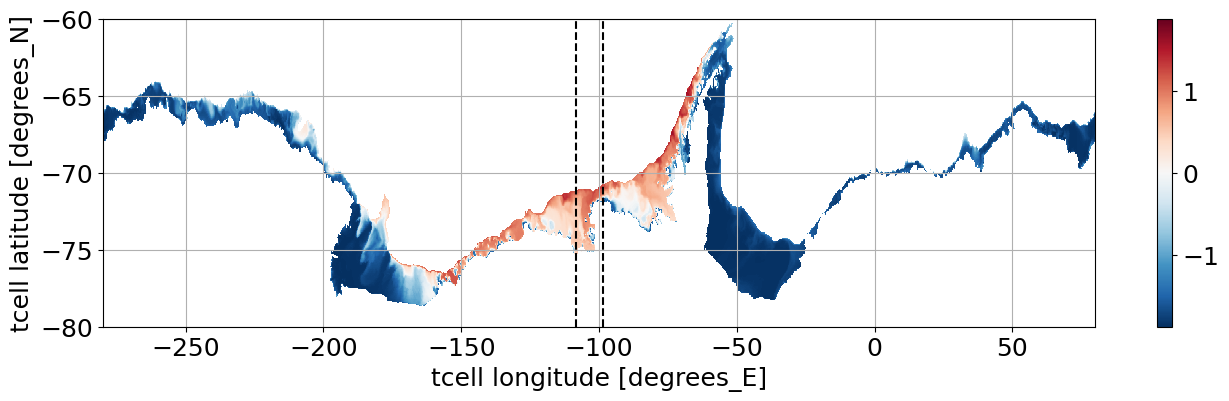

In [30]:
plt.figure(figsize=(16,4))
BT_iaf_shelf.plot()
plt.plot([-103.5-5,-103.5-5],[-80,-60],'--',color='k')
plt.plot([-103.5+5,-103.5+5],[-80,-60],'--',color='k')
plt.ylim(-80,-60)
plt.grid()

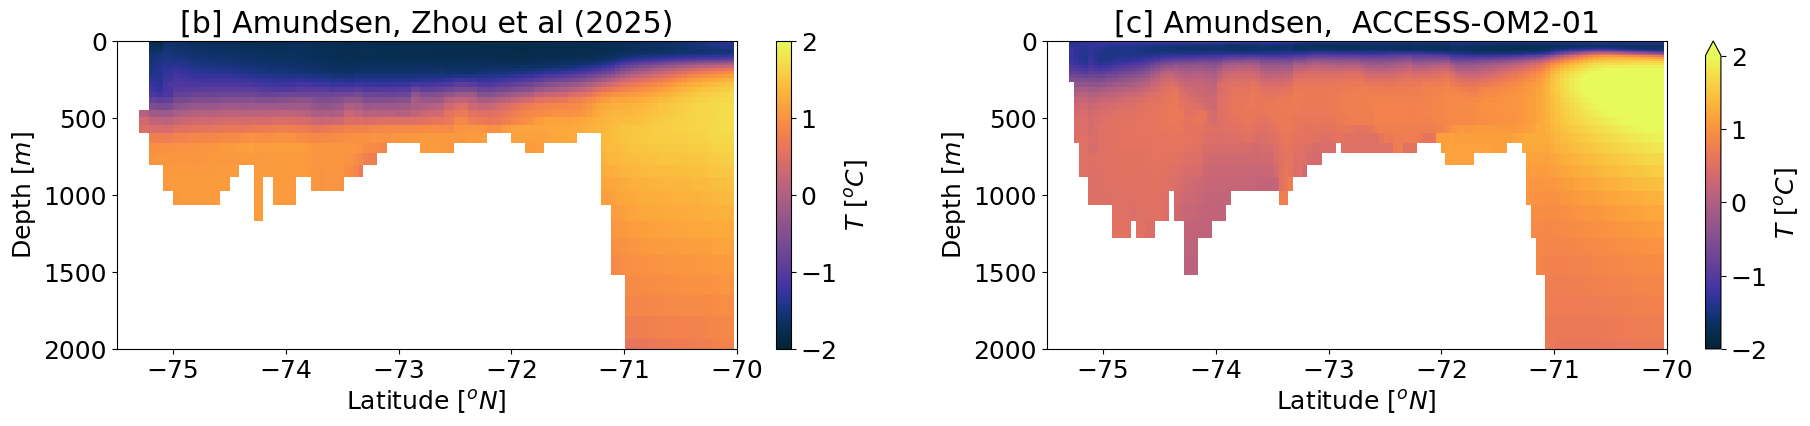

In [31]:
plt.figure(figsize=(22,4))
vmin=-2;vmax=2
cmapp=cm.thermal

plt.subplot(1,2,1)
Zhou_CT_inaccess.sel(xt_ocean=Amundsen_lon_slice,yt_ocean=Amundsen_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-75.5,-70)
plt.title('[b] Amundsen, Zhou et al (2025)')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')

plt.subplot(1,2,2)
T_iaf.sel(xt_ocean=Amundsen_lon_slice,yt_ocean=Amundsen_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-75.5,-70)
plt.title('[c] Amundsen,  ACCESS-OM2-01')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')
plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/Amundsen_obs_transects.png',dpi=300,bbox_inches='tight')

### Totten Transect

In [32]:
Totten_lon_slice = slice(-243.5-5,-243.5+5)
Totten_lat_slice = slice(-68,-62)

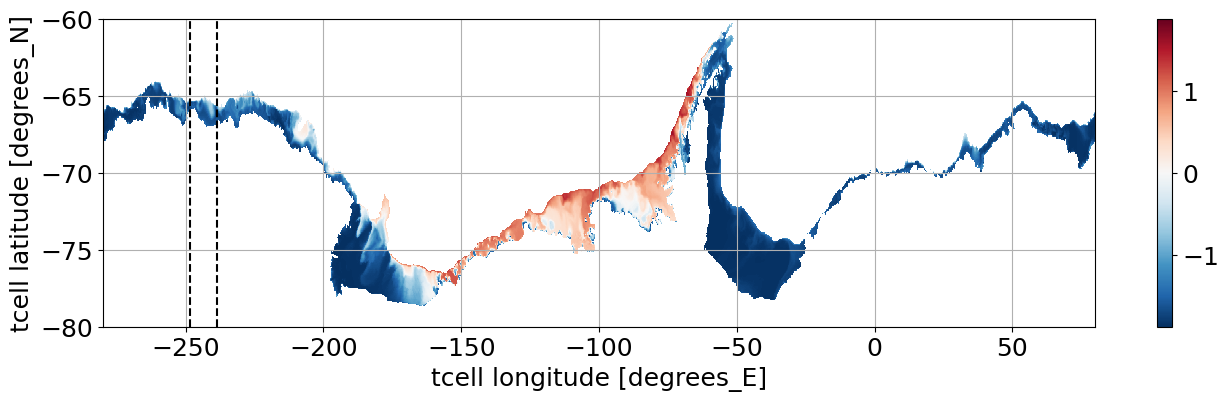

In [33]:
plt.figure(figsize=(16,4))
BT_iaf_shelf.plot()
plt.plot([-243.5-5,-243.5-5],[-80,-60],'--',color='k')
plt.plot([-243.5+5,-243.5+5],[-80,-60],'--',color='k')
plt.ylim(-80,-60)
plt.grid()

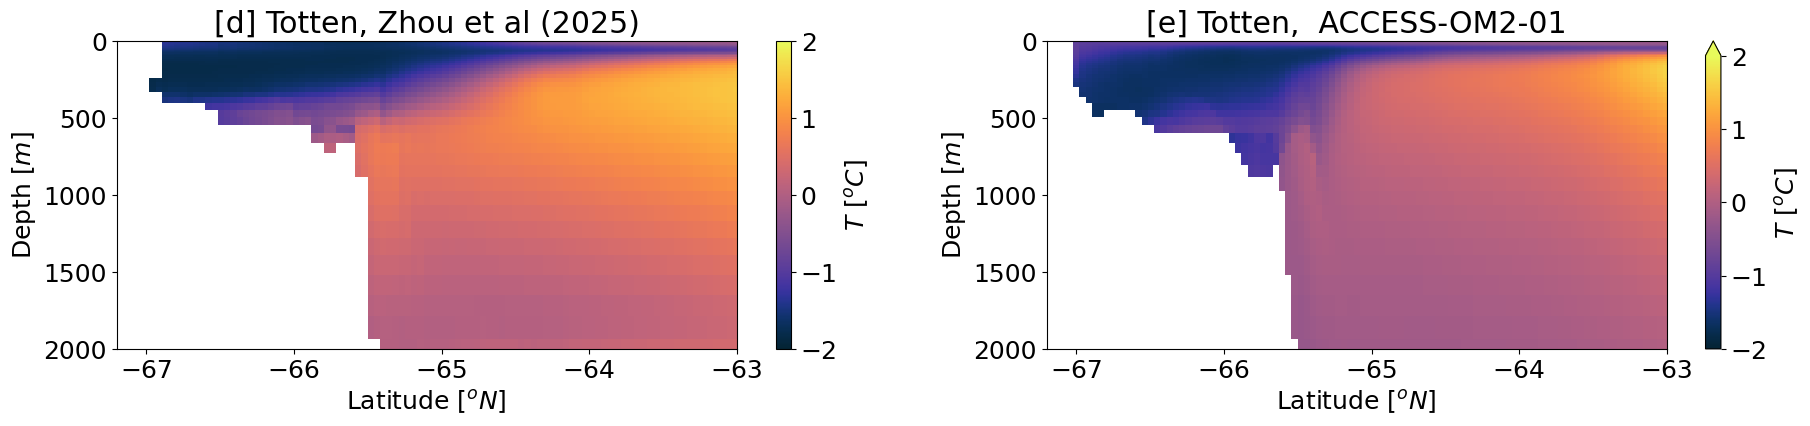

In [34]:
plt.figure(figsize=(22,4))
vmin=-2;vmax=2
cmapp=cm.thermal

plt.subplot(1,2,1)
Zhou_CT_inaccess.sel(xt_ocean=Totten_lon_slice,yt_ocean=Totten_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-67.2,-63)
plt.title('[d] Totten, Zhou et al (2025)')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')

plt.subplot(1,2,2)
T_iaf.sel(xt_ocean=Totten_lon_slice,yt_ocean=Totten_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-67.2,-63)
plt.title('[e] Totten,  ACCESS-OM2-01')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')
plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/Totten_obs_transects.png',dpi=300,bbox_inches='tight')

### 110 E Transect

In [35]:
L110_lon_slice = slice(-253.5-5,-253.5+5)
L110_lat_slice = slice(-68,-62)

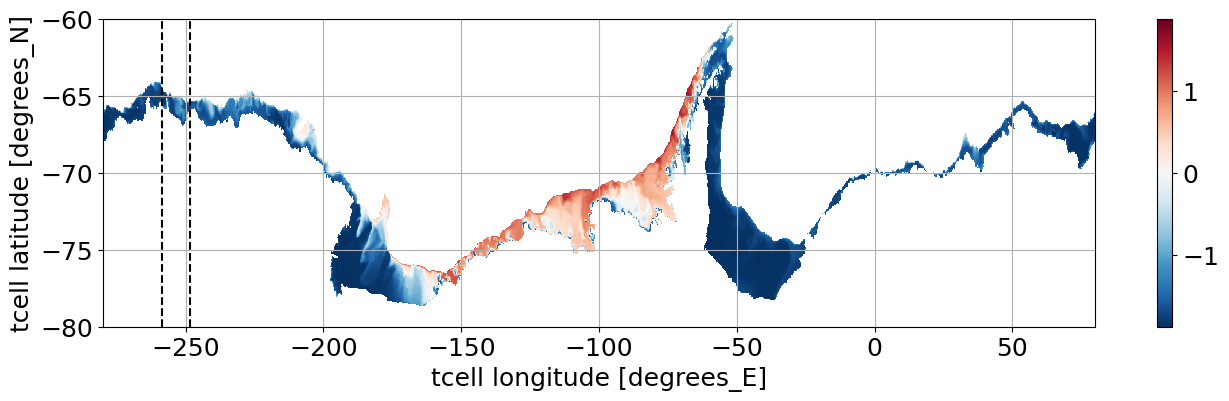

In [36]:
plt.figure(figsize=(16,4))
BT_iaf_shelf.plot()
plt.plot([-253.5-5,-253.5-5],[-80,-60],'--',color='k')
plt.plot([-253.5+5,-253.5+5],[-80,-60],'--',color='k')
plt.ylim(-80,-60)
plt.grid()

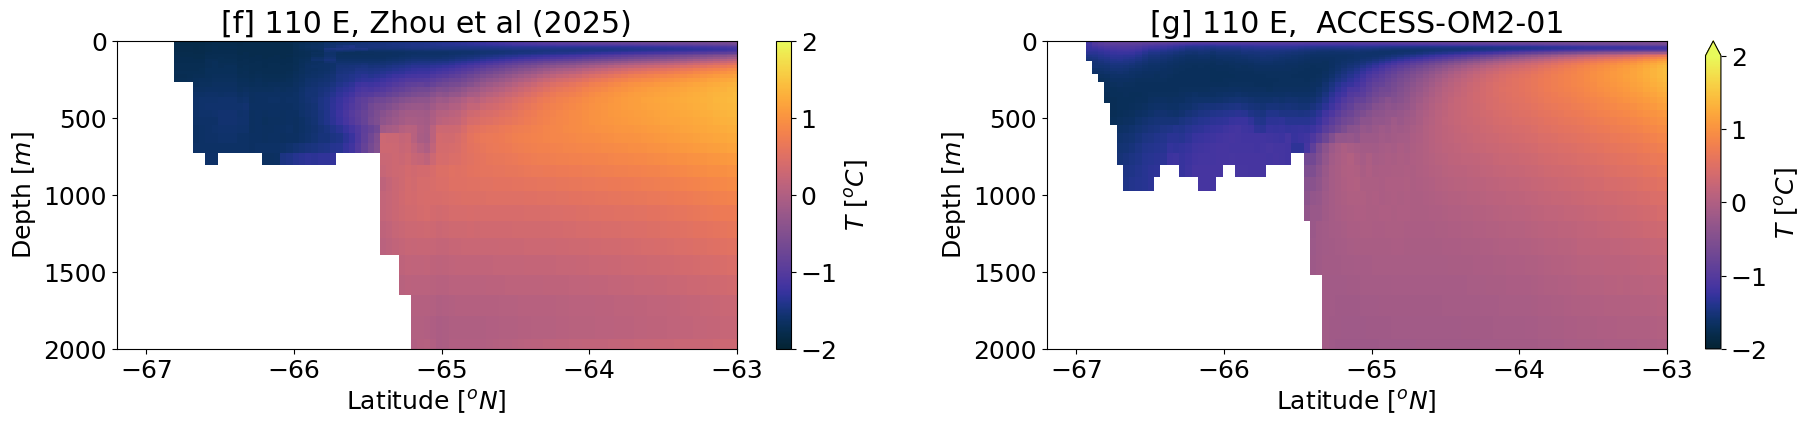

In [37]:
plt.figure(figsize=(22,4))
vmin=-2;vmax=2
cmapp=cm.thermal

plt.subplot(1,2,1)
Zhou_CT_inaccess.sel(xt_ocean=L110_lon_slice,yt_ocean=L110_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-67.2,-63)
plt.title('[f] 110 E, Zhou et al (2025)')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')

plt.subplot(1,2,2)
T_iaf.sel(xt_ocean=L110_lon_slice,yt_ocean=L110_lat_slice).mean('xt_ocean').plot(y='st_ocean',vmin=vmin,vmax=vmax,cmap=cmapp,cbar_kwargs={'label':'$T$ [$^{o}C$]'})
plt.ylim(2000,0)
plt.xlim(-67.2,-63)
plt.title('[g] 110 E,  ACCESS-OM2-01')
plt.ylabel(r'Depth [$m$]')
plt.xlabel(r'Latitude [$^oN$]')

plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/110E_obs_transects.png',dpi=300,bbox_inches='tight')

## Location of transects

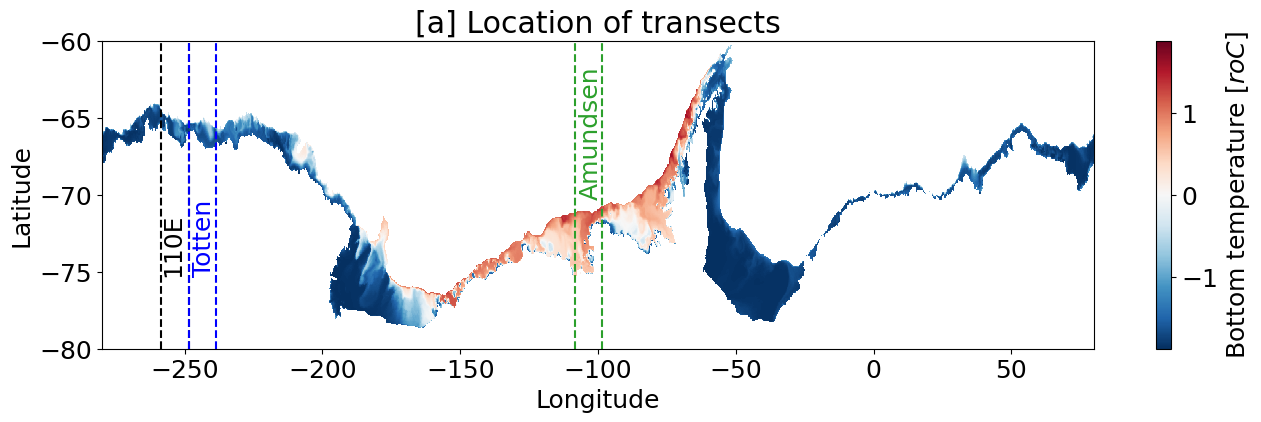

In [38]:
plt.figure(figsize=(16,4))
BT_iaf_shelf.plot(cbar_kwargs={'label':r'Bottom temperature [$roC$]'})
plt.plot([-253.5-5,-253.5-5],[-80,-60],'--',color='k')
plt.plot([-253.5+5,-253.5+5],[-80,-60],'--',color='k')
plt.text(-258.5,-75,'110E',rotation=90, color='k')

plt.plot([-243.5-5,-243.5-5],[-80,-60],'--',color='b')
plt.plot([-243.5+5,-243.5+5],[-80,-60],'--',color='b')
plt.text(-247.5,-75,'Totten',rotation=90, color='b')

plt.plot([-103.5-5,-103.5-5],[-80,-60],'--',color='tab:green')
plt.plot([-103.5+5,-103.5+5],[-80,-60],'--',color='tab:green')
plt.text(-107,-70,'Amundsen',rotation=90, color='tab:green')
plt.ylim(-80,-60)
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.title('[a] Location of transects')

plt.savefig('/g/data/x77/wf4500/ASC_project/analysis_figs/Transects_location.png',dpi=300,bbox_inches='tight')